In [452]:
import pandas as pd
from pathlib import Path
import glob
import json

import matplotlib.pyplot as plt

In [453]:
import re
SEED_PATTERN = re.compile(r"^(?P<source>.+?)_seed_?(?P<seed>\d+)$")

ALL_TEST_PHASES = ["simulation_full_year_potsdam", "simulation_full_year_garmisch", "simulation_full_year_mannheim", "simulation_full_year_hamburg", "simulation_full_year_essen"]
TEST_PHASE = "simulation_full_year_potsdam"

SOURCES_TO_COMPARE = ["all_closed", "hard_coded_control", "drl_ambient_adjusted", "drl_ambient_adjusted_weather_like_measured", "drl_ambient_adjusted_measured"]

name_to_short_label = {
    "all_closed": "Alle geschlossen",
    "random_control": "Zufallsbasiert",
    "hard_coded_control": "Regelbasiert",
    "drl_ambient_adjusted": "DQN-Sim\n(1 Jahr)",
    "drl_ambient_adjusted_measured": "DQN-Mess\n(2 Monate)",
    "drl_ambient_adjusted_weather_like_measured": "DQN-Sim\n(2 Monate)",

    "simulation_full_year_potsdam": "Potsdam",
    "simulation_full_year_garmisch": "Garmisch-Partenkirchen",
    "simulation_full_year_mannheim": "Mannheim",
    "simulation_full_year_hamburg": "Hamburg",
    "simulation_full_year_essen": "Essen"
}

CONTROL_ACTIONS = {
    "all_closed": 0, # for winter night
    "all_open": 2, # for summer night
    "inside_open": 1, # for winter day (with radiation)
    "outside_open": -1 # for summer day
}

# ---------- Einheitliche Farben für alle Abbildungen ----------
# Regelungsstrategien (Schlüssel = source; Seeds werden über split_source_seed auf die Basis-Strategie abgebildet)
STRATEGY_COLORS = {
    "all_closed": "#9c755f",
    "random_control": "#bab0ac",
    "hard_coded_control": "#7f7f7f",
    "drl_baseline": "#b279a2",
    "drl_ambient_adjusted": "#54A24B",                         # DQN-Sim (1 Jahr)
    "drl_ambient_adjusted_weather_like_measured": "#2a78d6",   # DQN-Sim (2 Monate)
    "drl_ambient_adjusted_measured": "#eb6834",                # DQN-Mess (2 Monate)
}

# Klappenstellungen (Schlüssel = Wert von control); bewusst andere Farbtöne als die Strategien
ACTION_NAMES = {0: "alle geschlossen", 1: "innen offen", -1: "außen offen", 2: "alle offen"}
ACTION_ORDER = [0, 1, -1, 2]
ACTION_COLORS = {0: "#3b4a6b", 1: "#e3a33b", -1: "#9b4f96", 2: "#5ec2c2"}

def strategy_color(source):
    """Farbe einer Strategie; Ordnernamen mit Seed (z. B. '..._seed3') bekommen die Farbe der Basis-Strategie."""
    base = SEED_PATTERN.match(source)["source"] if SEED_PATTERN.match(source) else source
    return STRATEGY_COLORS.get(base, "#333333")

def strategy_order_key(source):
    """Sortierschlüssel: Reihenfolge wie in SOURCES_TO_COMPARE (Seeds wie ihre Basis-Strategie, unbekannte ans Ende)."""
    base = SEED_PATTERN.match(source)["source"] if SEED_PATTERN.match(source) else source
    return SOURCES_TO_COMPARE.index(base) if base in SOURCES_TO_COMPARE else len(SOURCES_TO_COMPARE)

In [454]:
# def din_comfort_band(ambient_temp):
#     if ambient_temp < 16:
#         return (20, 22, 24)
#     elif ambient_temp < 32:
#         return (16 + 0.25 * ambient_temp, 18 + 0.25 * ambient_temp, 20 + 0.25 * ambient_temp)
#     else:
#         return (24, 26, 28)

def din_comfort_band(ambient_temp):
    return (20, 21, 22)

# Vektorisierte Variante (arbeitet auf ganzen Spalten statt Zeile für Zeile -> deutlich schneller)
# def din_comfort_band_vec(ambient_temp):
#     ambient_temp = np.asarray(ambient_temp, dtype=float)
#     lower = np.where(ambient_temp < 16, 20.0, np.where(ambient_temp < 32, 16 + 0.25 * ambient_temp, 24.0))
#     return lower, lower + 2, lower + 4

def din_comfort_band_vec(ambient_temp):
    ambient_temp = np.asarray(ambient_temp, dtype=float)
    lower = np.full_like(ambient_temp, 20.0)
    return lower, lower + 1, lower + 2

def inside_comfort_band(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if lower <= operative_temp <= upper:
        return True
    else:
        return False

def overheating_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp > upper:
        return operative_temp - upper
    else:
        return 0

def undercooling_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp < lower:
        return lower - operative_temp
    else:
        return 0

def median_run_data(df, metric="inside_comfort", verbose=True):
    """Nur den Median-Lauf je Strategie behalten (Ranking nach Summe von `metric`, Standard: Komfortstunden).
    Bei gerader Seed-Anzahl der untere der beiden mittleren Läufe; Strategien ohne Seeds bleiben unverändert.
    `df` sollte nur einen Standort (test_phase) enthalten."""
    runs = (
        df.groupby(["source", "seed"], dropna=False)[metric].sum()
        .reset_index().sort_values(["source", metric])
    )
    grouped = runs.groupby("source")
    median_runs = runs[grouped.cumcount() == (grouped[metric].transform("size") - 1) // 2]
    if verbose:
        print("Median runs:", ", ".join(f"{s} (seed {sd})" for s, sd in zip(median_runs["source"], median_runs["seed"])))
    run_key = df["source"] + "|" + df["seed"].astype("string").fillna("-")
    median_keys = set(median_runs["source"] + "|" + median_runs["seed"].astype("string").fillna("-"))
    return df[run_key.isin(median_keys)]

In [455]:
import re
import numpy as np

SEED_PATTERN = re.compile(r"^(?P<source>.+?)_seed_?(?P<seed>\d+)$")

def split_source_seed(dir_name):
    """'drl_ambient_adjusted_seed1' / '..._seed_1' -> ('drl_ambient_adjusted', 1); ohne Seed -> (name, None)."""
    match = SEED_PATTERN.match(dir_name)
    if match:
        return match["source"], int(match["seed"])
    return dir_name, None

def flatten_record(record):
    # Records sind nur eine Ebene verschachtelt ({"misc": {...}, "state": {...}, "control": 1, ...}).
    # Direktes Flachklopfen ist viel schneller als pd.json_normalize; Spaltennamen = letzter Schlüssel.
    flat = {}
    for key, value in record.items():
        if isinstance(value, dict):
            flat.update(value)
        else:
            flat[key] = value
    return flat

def load_source(source_path):
    rows = []
    for file_path in source_path.glob("*.jsonl"):
        with open(file_path, encoding="utf-8") as file:
            rows.extend(flatten_record(json.loads(line)) for line in file if line.strip())
    return pd.DataFrame(rows) if rows else None

phase_frames = []
start_date = pd.Timestamp("2024-01-01")

for test_phase in ALL_TEST_PHASES:
    results_path = Path(fr"C:\Users\lkclu\Documents\GitHub\DTFS\results\control\{test_phase}")

    frames = []
    for source_path in results_path.iterdir():
        if not source_path.is_dir():
            continue
        source, seed = split_source_seed(source_path.name)
        if source not in SOURCES_TO_COMPARE:
            continue  # nicht benötigte Quellen gar nicht erst einlesen
        frame = load_source(source_path)
        if frame is None:
            continue
        frame["source"] = source
        frame["seed"] = seed
        frames.append(frame)

    if not frames:
        raise FileNotFoundError(f"No JSONL result files found in {results_path}")

    phase_data = pd.concat(frames, ignore_index=True)
    phase_data["seed"] = phase_data["seed"].astype("Int64")
    phase_data["datetime"] = start_date + pd.to_timedelta(phase_data["current_time"], unit="h")

    t_amb = phase_data["dry_bulb_temperature"].to_numpy(dtype=float)
    t_op = phase_data["operative_temperature"].to_numpy(dtype=float)
    t_low, t_mid, t_high = din_comfort_band_vec(t_amb)
    phase_data["t_low"], phase_data["t_mid"], phase_data["t_high"] = t_low, t_mid, t_high
    phase_data["inside_comfort"] = (t_op >= t_low) & (t_op <= t_high)
    phase_data["overheating"] = np.clip(t_op - t_high, 0, None)
    phase_data["undercooling"] = np.clip(t_low - t_op, 0, None)
    phase_data["test_phase"] = test_phase

    phase_frames.append(phase_data)

all_data = pd.concat(phase_frames, ignore_index=True)
all_data.groupby(["test_phase", "source"], dropna=False)["seed"].unique()

test_phase                     source                                    
simulation_full_year_essen     all_closed                                             [<NA>]
                               drl_ambient_adjusted                          [1, 2, 3, 4, 5]
                               drl_ambient_adjusted_measured                          [<NA>]
                               drl_ambient_adjusted_weather_like_measured    [1, 2, 3, 4, 5]
                               hard_coded_control                                     [<NA>]
simulation_full_year_garmisch  all_closed                                             [<NA>]
                               drl_ambient_adjusted                          [1, 2, 3, 4, 5]
                               drl_ambient_adjusted_measured                          [<NA>]
                               drl_ambient_adjusted_weather_like_measured    [1, 2, 3, 4, 5]
                               hard_coded_control                                     [<N

In [456]:
all_data.head()

,hour_of_day,current_time,dry_bulb_temperature,total_horizontal_radiation,operative_temperature,control,source,seed,datetime,t_low,t_mid,t_high,inside_comfort,overheating,undercooling,test_phase
0,0.166667,0.166667,-0.95,0.0,20.613411,0,all_closed,<NA>,2024-01-01 00:10:00.000000001,20.0,21.0,22.0,True,0.0,0.000000,simulation_full_year_potsdam
1,0.333333,0.333333,-1.25,0.0,19.894366,0,all_closed,<NA>,2024-01-01 00:19:59.999999998,20.0,21.0,22.0,False,0.0,0.105634,simulation_full_year_potsdam
2,0.500000,0.500000,-1.55,0.0,19.274803,0,all_closed,<NA>,2024-01-01 00:30:00.000000000,20.0,21.0,22.0,False,0.0,0.725197,simulation_full_year_potsdam
3,0.666667,0.666667,-1.85,0.0,18.738566,0,all_closed,<NA>,2024-01-01 00:40:00.000000001,20.0,21.0,22.0,False,0.0,1.261434,simulation_full_year_potsdam
4,0.833333,0.833333,-2.15,0.0,18.272105,0,all_closed,<NA>,2024-01-01 00:49:59.999999998,20.0,21.0,22.0,False,0.0,1.727895,simulation_full_year_potsdam


In [457]:
all_data["test_phase"].unique()

array(['simulation_full_year_potsdam', 'simulation_full_year_garmisch',
       'simulation_full_year_mannheim', 'simulation_full_year_hamburg',
       'simulation_full_year_essen'], dtype=object)

In [458]:
data = all_data[all_data["test_phase"] == TEST_PHASE]

In [459]:
data.head()

,hour_of_day,current_time,dry_bulb_temperature,total_horizontal_radiation,operative_temperature,control,source,seed,datetime,t_low,t_mid,t_high,inside_comfort,overheating,undercooling,test_phase
0,0.166667,0.166667,-0.95,0.0,20.613411,0,all_closed,<NA>,2024-01-01 00:10:00.000000001,20.0,21.0,22.0,True,0.0,0.000000,simulation_full_year_potsdam
1,0.333333,0.333333,-1.25,0.0,19.894366,0,all_closed,<NA>,2024-01-01 00:19:59.999999998,20.0,21.0,22.0,False,0.0,0.105634,simulation_full_year_potsdam
2,0.500000,0.500000,-1.55,0.0,19.274803,0,all_closed,<NA>,2024-01-01 00:30:00.000000000,20.0,21.0,22.0,False,0.0,0.725197,simulation_full_year_potsdam
3,0.666667,0.666667,-1.85,0.0,18.738566,0,all_closed,<NA>,2024-01-01 00:40:00.000000001,20.0,21.0,22.0,False,0.0,1.261434,simulation_full_year_potsdam
4,0.833333,0.833333,-2.15,0.0,18.272105,0,all_closed,<NA>,2024-01-01 00:49:59.999999998,20.0,21.0,22.0,False,0.0,1.727895,simulation_full_year_potsdam


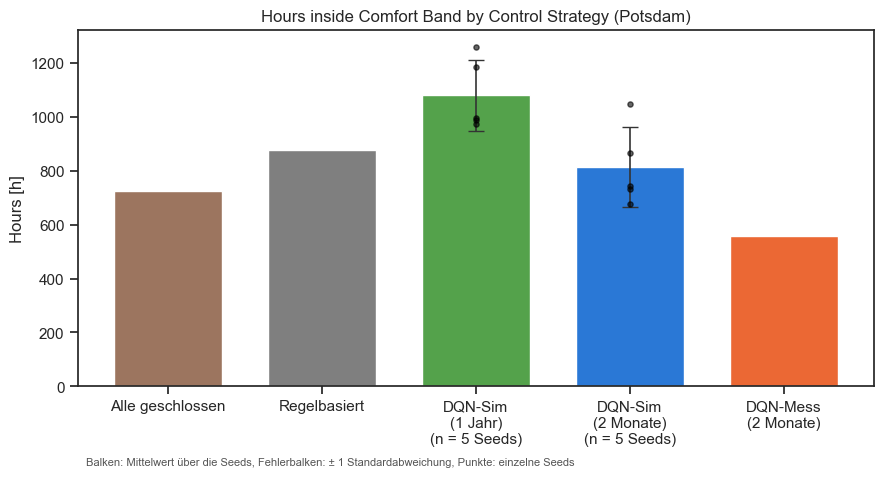

,mean,std,count
source,,,
Alle geschlossen,725.5,NaN,1
Regelbasiert,876.8,NaN,1
DQN-Sim (1 Jahr),1079.2,132.0,5
DQN-Sim (2 Monate),812.4,149.0,5
DQN-Mess (2 Monate),557.5,NaN,1


In [460]:
# Komfortstunden je (source, seed); Quellen ohne Seed haben seed = <NA>
comfort_per_seed = (
    data.groupby(["source", "seed"], dropna=False)["inside_comfort"].sum() / 6
).rename("Comfort hours").reset_index()

# Mittelwert und Standardabweichung über die Seeds (kein Fehlerbalken bei nur einem Lauf)
summary = (
    comfort_per_seed.groupby("source")["Comfort hours"]
    .agg(["mean", "std", "count"])
    .reindex(SOURCES_TO_COMPARE).dropna(subset=["mean"])
)

x = np.arange(len(summary))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, summary["mean"], width=0.7, color=[strategy_color(s) for s in summary.index],
       yerr=summary["std"].where(summary["count"] > 1), capsize=6, error_kw=dict(ecolor="#333333", lw=1.2))

# einzelne Seeds als Punkte
for i, source in enumerate(summary.index):
    values = comfort_per_seed.loc[comfort_per_seed["source"] == source, "Comfort hours"]
    if len(values) > 1:
        ax.scatter(np.full(len(values), i), values, s=14, color="black", alpha=0.6, zorder=3)

labels = [
    name_to_short_label.get(source, source) + (f"\n(n = {int(n)} Seeds)" if n > 1 else "")
    for source, n in zip(summary.index, summary["count"])
]
ax.set_xticks(x, labels)
ax.set_ylabel("Hours [h]")
ax.set_title(f"Hours inside Comfort Band by Control Strategy ({name_to_short_label.get(TEST_PHASE, TEST_PHASE)})")
ax.text(0.01, -0.22, "Balken: Mittelwert über die Seeds, Fehlerbalken: ± 1 Standardabweichung, Punkte: einzelne Seeds",
        transform=ax.transAxes, fontsize=8, color="#555555")
plt.tight_layout()
plt.show()

summary.rename(index=lambda s: name_to_short_label.get(s, s).replace("\n", " ")).round(1)

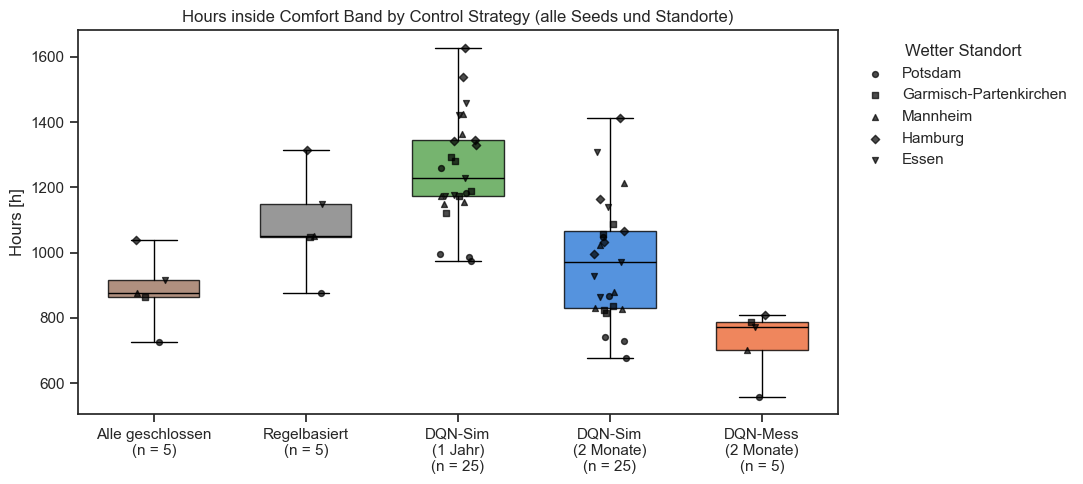

In [461]:
# one comfort-hours value per run (source, seed, test_phase)
comfort_per_run = (
    all_data.groupby(["source", "seed", "test_phase"], dropna=False)["inside_comfort"].sum() / 6  # 10-min-Schritte -> Stunden
).rename("Comfort hours").reset_index()

# keep order of SOURCES_TO_COMPARE and drop sources without data
sources = [s for s in SOURCES_TO_COMPARE if s in comfort_per_run["source"].unique()]

# alle Läufe (Seeds × Standorte) je Strategie
box_data = [comfort_per_run.loc[comfort_per_run["source"] == s, "Comfort hours"].values for s in sources]
labels = [f"{name_to_short_label.get(s, s)}\n(n = {len(v)})" for s, v in zip(sources, box_data)]

# plot
fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(box_data, patch_artist=True, widths=0.6, tick_labels=labels, whis=(0, 100))

for patch, source in zip(bp["boxes"], sources):
    patch.set_facecolor(strategy_color(source))
    patch.set_alpha(0.8)
for median in bp["medians"]:
    median.set_color("black")

# overlay the individual runs, eine Markerform je Standort (leicht horizontal verteilt)
PHASE_MARKERS = dict(zip(ALL_TEST_PHASES, ["o", "s", "^", "D", "v", "P", "X"]))
rng = np.random.default_rng(0)
for i, source in enumerate(sources, start=1):
    runs = comfort_per_run[comfort_per_run["source"] == source]
    for phase, marker in PHASE_MARKERS.items():
        values = runs.loc[runs["test_phase"] == phase, "Comfort hours"].values
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, marker=marker,
                   color="black", s=18, alpha=0.7, zorder=3,
                   label=name_to_short_label.get(phase, phase) if i == 1 else None)
ax.legend(title="Wetter Standort", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

ax.set_ylabel("Hours [h]")
ax.set_xlabel("")
ax.set_title("Hours inside Comfort Band by Control Strategy (alle Seeds und Standorte)")
plt.tight_layout()
plt.show()

Median runs: all_closed (seed <NA>), drl_ambient_adjusted (seed 2), drl_ambient_adjusted_measured (seed <NA>), drl_ambient_adjusted_weather_like_measured (seed 5), hard_coded_control (seed <NA>)
262770
13138


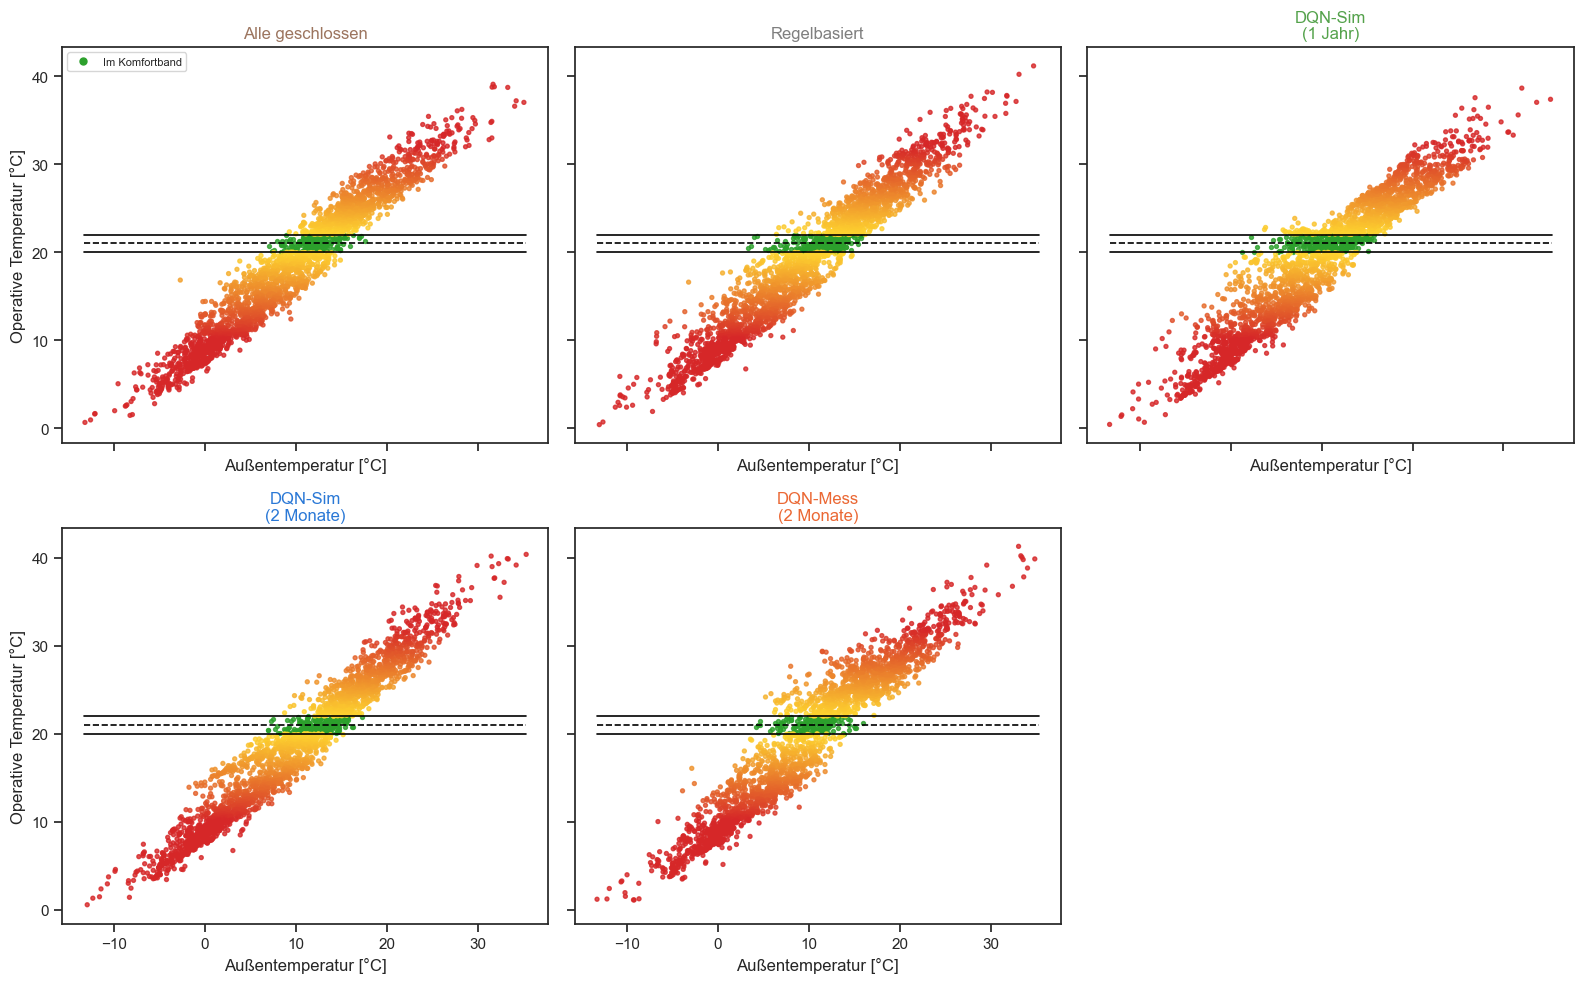

In [462]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# Median run je Strategie (nach Komfortstunden am gewählten Standort)
median_data = median_run_data(data)

print(len(median_data))
selected_data = median_data.sample(frac=0.05, random_state=42)
print(len(selected_data))

# Abweichung vom Komfortband in K (0 = im Band)
selected_data = selected_data.assign(
    deviation=selected_data["overheating"] + selected_data["undercooling"]
)

# Innen: feste Farbe. Außen: Gelb -> Rot
INSIDE_COLOR = "#2ca02c"
cmap = LinearSegmentedColormap.from_list("yellow_red", ["#ffd92f", "#d62728"])
MAX_DEV = 10.0   # ab dieser Abweichung [K] ist der Punkt voll rot
norm = Normalize(vmin=0, vmax=MAX_DEV, clip=True)

x_range = np.linspace(
    selected_data["dry_bulb_temperature"].min(),
    selected_data["dry_bulb_temperature"].max(),
    200,
)
lower, mid, upper = zip(*[din_comfort_band(t) for t in x_range])

n_cols = 3
n_rows = int(np.ceil(len(SOURCES_TO_COMPARE) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows), sharex=True, sharey=True, squeeze=False)
for ax in axes.flat[len(SOURCES_TO_COMPARE):]:
    ax.set_visible(False)

for ax, source in zip(axes.flat, SOURCES_TO_COMPARE):
    subset = selected_data[selected_data["source"] == source]
    label = name_to_short_label.get(source, source)

    if not subset.empty:
        inside = subset[subset["deviation"] <= 0]
        outside = subset[subset["deviation"] > 0].sort_values("deviation")  # schlimmste oben

        ax.scatter(
            inside["dry_bulb_temperature"], inside["operative_temperature"],
            s=8, alpha=0.8, color=INSIDE_COLOR,
        )
        ax.scatter(
            outside["dry_bulb_temperature"], outside["operative_temperature"],
            s=8, alpha=0.8, c=outside["deviation"], cmap=cmap, norm=norm,
        )

    ax.plot(x_range, lower, "-", color="black", linewidth=1.2)
    ax.plot(x_range, upper, "-", color="black", linewidth=1.2)
    ax.plot(x_range, mid, "--", color="black", linewidth=1.2)
    ax.set_title(label, color=strategy_color(source))

for ax in axes.flat:
    ax.set_xlabel("Außentemperatur [°C]")
for ax in axes[:, 0]:
    ax.set_ylabel("Operative Temperatur [°C]")

fig.tight_layout()

# Colorbar nur für Punkte außerhalb des Bands
# cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=0.8, pad=0.02)
# cbar.set_label("Abweichung vom Komfortband [K]")

# Legendeneintrag für "im Band"
axes[0, 0].legend(
    handles=[Line2D([], [], marker="o", linestyle="", color=INSIDE_COLOR,
                    markersize=5, label="Im Komfortband")],
    loc="upper left", fontsize=8,
)
fig.savefig("comfort_scatter.svg", format="svg", bbox_inches="tight")
plt.show()

Median runs: all_closed (seed <NA>), drl_ambient_adjusted (seed 2), drl_ambient_adjusted_measured (seed <NA>), drl_ambient_adjusted_weather_like_measured (seed 5), hard_coded_control (seed <NA>)


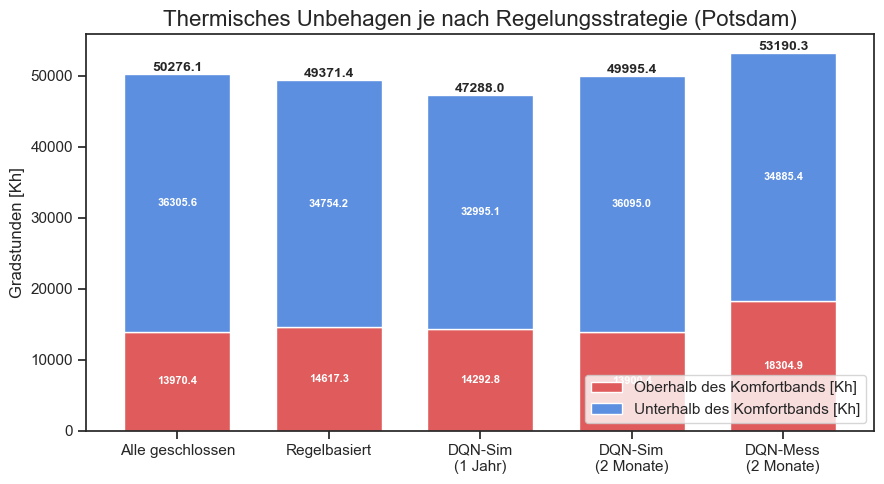

In [463]:
# nur der Median run je Strategie (nach Komfortstunden, wie im Scatter-Plot)
median_data = median_run_data(data)
overheating_kh = median_data.groupby("source")["overheating"].sum() / 6
undercooling_kh = median_data.groupby("source")["undercooling"].sum() / 6

summary = pd.DataFrame({
    "Oberhalb des Komfortbands [Kh]": overheating_kh,
    "Unterhalb des Komfortbands [Kh]": undercooling_kh,
}).reindex(SOURCES_TO_COMPARE).dropna()
summary.index = [name_to_short_label.get(source, source) for source in summary.index]

# plot
ax = summary.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#e05c5c", "#5c8fe0"], width=0.7)

# annotate each segment
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.1f", label_type="center", fontsize=8, color="white", fontweight="bold")

# annotate total on top
for i, total in enumerate(summary.sum(axis=1)):
    ax.text(i, total + 0.5, f"{total:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

plt.ylabel("Gradstunden [Kh]")
plt.xlabel("")
plt.title(f"Thermisches Unbehagen je nach Regelungsstrategie ({name_to_short_label.get(TEST_PHASE, TEST_PHASE)})")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

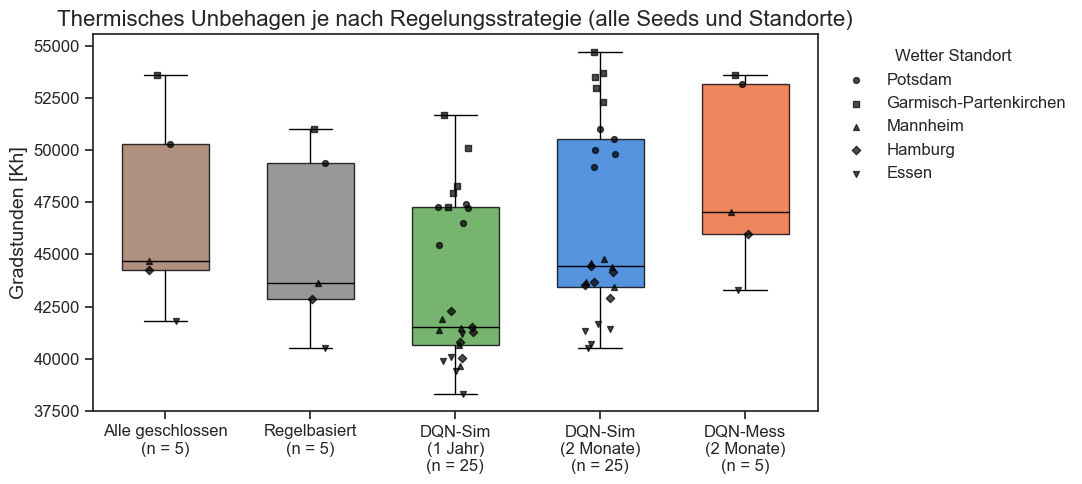

In [464]:
# one total discomfort value (Kh) per run (source, seed, test_phase)
discomfort_per_run = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "seed", "test_phase"], dropna=False)["total_discomfort"].sum() / 6
).rename("Discomfort Kh").reset_index()

# keep order of SOURCES_TO_COMPARE and drop sources without data
sources = [s for s in SOURCES_TO_COMPARE if s in discomfort_per_run["source"].unique()]

# alle Läufe (Seeds × Standorte) je Strategie
box_data = [discomfort_per_run.loc[discomfort_per_run["source"] == s, "Discomfort Kh"].values for s in sources]
labels = [f"{name_to_short_label.get(s, s)}\n(n = {len(v)})" for s, v in zip(sources, box_data)]

# plot
fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(box_data, patch_artist=True, widths=0.6, tick_labels=labels, whis=(0, 100))

for patch, source in zip(bp["boxes"], sources):
    patch.set_facecolor(strategy_color(source))
    patch.set_alpha(0.8)
for median in bp["medians"]:
    median.set_color("black")

# overlay the individual runs, eine Markerform je Standort (leicht horizontal verteilt)
PHASE_MARKERS = dict(zip(ALL_TEST_PHASES, ["o", "s", "^", "D", "v", "P", "X"]))
rng = np.random.default_rng(0)
for i, source in enumerate(sources, start=1):
    runs = discomfort_per_run[discomfort_per_run["source"] == source]
    for phase, marker in PHASE_MARKERS.items():
        values = runs.loc[runs["test_phase"] == phase, "Discomfort Kh"].values
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, marker=marker,
                   color="black", s=18, alpha=0.7, zorder=3,
                   label=name_to_short_label.get(phase, phase) if i == 1 else None)
ax.legend(title="Wetter Standort", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

ax.set_ylabel("Gradstunden [Kh]")
ax.set_xlabel("")
ax.set_title("Thermisches Unbehagen je nach Regelungsstrategie (alle Seeds und Standorte)")
plt.tight_layout()
plt.show()

# Analyse: Trainingsdauer und Sim-Real-Gap

Zwei Fragen:

1. **Warum sind die 2-Monats-Agenten schlechter als die 1-Jahres-Agenten?** Liegt es nur daran, dass sie das Wetter im Rest des Jahres nie gesehen haben (dann müssten sie bei ähnlichem Wetter ähnlich gut sein), oder sind sie auch bei bekanntem Wetter schlechter?
2. **Ist DQN-sim besser als DQN-real, und warum?** Gibt es einen Sim-Real-Gap?

| Kurzname | Ordner | Training | Schritte je Lauf |
|---|---|---|---|
| DQN-sim 1 Jahr | `drl_ambient_adjusted_seed1–5` | Zwilling, Standardwetter, ganzes Jahr | ≈ 52 500 |
| DQN-sim 2 Monate | `drl_ambient_adjusted_weather_like_measured_seed1–5` | Zwilling, Messwetter, 7.9.–16.11. | ≈ 10 000 |
| DQN-real 2 Monate | `drl_ambient_adjusted_measured` | Feldmessdaten, 7.9.–16.11. | ≈ 8 700 |

Alle drei Agenten haben dieselbe Belohnung (`ambient_adjusted`) und dieselben Eingänge (Außentemperatur, Strahlung, operative Temperatur).
Getestet wird überall im Zwilling (Jahressimulation, 5 Standorte).
Bewertet wird mit dem **festen Komfortband 20–22 °C**, also demselben Band wie in der Belohnung (Spalten `overheating`, `undercooling`, `inside_comfort` aus `all_data`).

In [465]:
# ---------- Setup ----------
REPO = Path(r"C:\Users\lkclu\Documents\GitHub\DTFS")
TIMESTEP_H = 1 / 6                         # 10-min-Zeitschritte
TRAIN_START_H, TRAIN_END_H = 5994, 7670    # 7.9.-16.11. (Stunden ab 1.1.), Trainingszeitraum der 2-Monats-Agenten

AGENTS = {  # source in all_data -> Kurzname
    "hard_coded_control": "Regelbasiert",
    "drl_ambient_adjusted": "DQN-sim 1 Jahr",
    "drl_ambient_adjusted_weather_like_measured": "DQN-sim 2 Monate",
    "drl_ambient_adjusted_measured": "DQN-real 2 Monate",
}
AGENT_ORDER = [AGENTS[s] for s in SOURCES_TO_COMPARE if s in AGENTS]      # Reihenfolge wie SOURCES_TO_COMPARE
DQN_AGENTS = [a for a in AGENT_ORDER if a != "Regelbasiert"]
TRAINING_RUNS = {  # Kurzname -> Ordner in results/models/online (Trainingsdaten)
    "DQN-sim 1 Jahr": [f"drl_ambient_adjusted_seed{s}" for s in range(1, 6)],
    "DQN-sim 2 Monate": [f"drl_ambient_adjusted_weather_like_measured_seed{s}" for s in range(1, 6)],
    "DQN-real 2 Monate": ["drl_ambient_adjusted_measured"],
}
AGENT_COLORS = {name: strategy_color(source) for source, name in AGENTS.items()}   # aus STRATEGY_COLORS (Zelle 1)
CITY_MARKERS = {name_to_short_label.get(p, p): m for p, m in zip(ALL_TEST_PHASES, ["o", "s", "^", "D", "v", "P", "X"])}
# ACTION_NAMES, ACTION_ORDER, ACTION_COLORS: siehe Zelle 1

missing = [s for s in AGENTS if s not in set(all_data["source"])]
assert not missing, f"Nicht in all_data geladen: {missing} -> in SOURCES_TO_COMPARE aufnehmen"

ev = all_data[all_data["source"].isin(AGENTS)].copy()
ev["agent"] = ev["source"].map(AGENTS)
ev["city"] = ev["test_phase"].map(lambda p: name_to_short_label.get(p, p))
ev["step"] = (ev["current_time"] * 6).round().astype(int)
ev["kh"] = ev["overheating"] + ev["undercooling"]
ev["outside"] = ~ev["inside_comfort"]
ev["in_train_period"] = (ev["current_time"] >= TRAIN_START_H) & (ev["current_time"] < TRAIN_END_H)
ev["run"] = ev["agent"] + " | " + ev["city"] + " | seed " + ev["seed"].astype("string").fillna("-")
print(ev.groupby("agent")["run"].nunique().rename("Läufe"))

agent
DQN-real 2 Monate     5
DQN-sim 1 Jahr       25
DQN-sim 2 Monate     25
Regelbasiert          5
Name: Läufe, dtype: int64


## 0. Konsistenzprüfung der Testläufe

Alle Läufe eines Standorts sollten exakt dieselben Wetter-Eingänge haben wie der regelbasierte Lauf.
Läufe, bei denen Außentemperatur oder Strahlung abweichen (z. B. weil sie mit einer älteren Version der Wetterdatei simuliert wurden), sind nicht vergleichbar und werden mit `EXCLUDE_INCONSISTENT = True` ausgeschlossen.

In [466]:
# ---------- 0. Haben alle Läufe dieselben Wetter-Eingänge wie der regelbasierte Lauf? ----------
EXCLUDE_INCONSISTENT = True

ref_weather = (ev[ev["agent"] == "Regelbasiert"]
               .set_index(["test_phase", "step"])[["dry_bulb_temperature", "total_horizontal_radiation"]])
chk = ev.join(ref_weather, on=["test_phase", "step"], rsuffix="_rb")
chk["d_t_amb"] = (chk["dry_bulb_temperature"] - chk["dry_bulb_temperature_rb"]).abs()
chk["d_rad"] = (chk["total_horizontal_radiation"] - chk["total_horizontal_radiation_rb"]).abs() > 1.0
consistency = chk.groupby(["run", "agent", "city"]).agg(
    max_abw_T_amb=("d_t_amb", "max"),
    anteil_abw_strahlung=("d_rad", "mean"),
    max_strahlung=("total_horizontal_radiation", "max"),
).reset_index()
consistency["konsistent"] = (consistency["max_abw_T_amb"] < 0.01) & (consistency["anteil_abw_strahlung"] < 0.001)
inconsistent_runs = consistency.loc[~consistency["konsistent"], "run"].tolist()

if inconsistent_runs:
    print(f"{len(inconsistent_runs)} Läufe mit anderen Wetter-Eingängen als der regelbasierte Lauf:")
    display(consistency[~consistency["konsistent"]].round(3))
    if EXCLUDE_INCONSISTENT:
        ev = ev[~ev["run"].isin(inconsistent_runs)].copy()
        print("-> ausgeschlossen. Verbleibende Läufe je Agent:")
        print(ev.groupby("agent")["run"].nunique())
else:
    print("Alle Läufe haben dieselben Wetter-Eingänge.")

Alle Läufe haben dieselben Wetter-Eingänge.


In [467]:
# ---------- Kennzahlen je Lauf und Zeitraum, relativ zum regelbasierten Regler am selben Standort ----------
PERIODS = {"Ganzes Jahr": None, "Trainingszeitraum\n(7.9.–16.11.)": True, "Rest des Jahres": False}

kpi_frames = []
for period, flag in PERIODS.items():
    sub = ev if flag is None else ev[ev["in_train_period"] == flag]
    k = (sub.groupby(["agent", "city", "seed", "run"], dropna=False)[["kh", "outside", "undercooling", "overheating"]]
         .sum().mul(TIMESTEP_H).reset_index())
    k["period"] = period
    kpi_frames.append(k)
kpi = pd.concat(kpi_frames, ignore_index=True)
kpi_rb = kpi[kpi["agent"] == "Regelbasiert"].set_index(["city", "period"])[["kh", "outside"]]
kpi = kpi.join(kpi_rb, on=["city", "period"], rsuffix="_rb")
kpi["d_kh"] = (kpi["kh"] / kpi["kh_rb"] - 1) * 100
kpi["d_hours"] = (kpi["outside"] / kpi["outside_rb"] - 1) * 100

def fmt(s):
    return f"{s.median():+.1f} % [{s.min():+.1f}, {s.max():+.1f}]"

kpi_summary = (kpi[kpi["agent"] != "Regelbasiert"]
               .groupby(["period", "agent"], sort=False)
               .agg(n=("run", "size"), **{"Kh vs. regelbasiert": ("d_kh", fmt),
                                          "Stunden außerhalb vs. regelbasiert": ("d_hours", fmt)}))
kpi_summary = kpi_summary.reindex(pd.MultiIndex.from_product([list(PERIODS), DQN_AGENTS], names=["period", "agent"]))
kpi_summary.index = kpi_summary.index.set_levels(kpi_summary.index.levels[0].str.replace("\n", " "), level=0)
print("Median [Min, Max] über alle Läufe (Seeds × Standorte):")
kpi_summary

Median [Min, Max] über alle Läufe (Seeds × Standorte):


n    Kh vs. regelbasiert  \
period                          agent                                          
Ganzes Jahr                     DQN-sim 1 Jahr     25    -4.4 % [-9.2, +1.7]   
                                DQN-sim 2 Monate   25    +2.2 % [-0.5, +7.3]   
                                DQN-real 2 Monate   5    +7.3 % [+5.1, +7.8]   
Trainingszeitraum (7.9.–16.11.) DQN-sim 1 Jahr     25  -13.3 % [-21.0, +2.6]   
                                DQN-sim 2 Monate   25    +2.3 % [-7.0, +7.9]   
                                DQN-real 2 Monate   5   +9.7 % [+5.6, +14.4]   
Rest des Jahres                 DQN-sim 1 Jahr     25    -3.6 % [-7.6, +2.6]   
                                DQN-sim 2 Monate   25    +2.2 % [+0.2, +7.2]   
                                DQN-real 2 Monate   5    +6.9 % [+5.0, +7.1]   

                                                  Stunden außerhalb vs. regelbasiert  
period                          agent                                                 
Ganzes Jahr                     DQN-sim 1 Jahr                   -1.6 % [-4.9, -0.2]  
                                DQN-sim 2 Monate                 +2.2 % [-2.2, +4.3]  
                                DQN-real 2 Monate                +4.5 % [+3.4, +6.8]  
Trainingszeitraum (7.9.–16.11.) DQN-sim 1 Jahr                  -4.9 % [-14.8, -0.2]  
                                DQN-sim 2 Monate                 +2.3 % [-8.3, +9.3]  
                                DQN-real 2 Monate                +3.9 % [+2.2, +5.4]  
Rest des Jahres                 DQN-sim 1 Jahr                   -1.0 % [-3.3, +0.5]  
                                DQN-sim 2 Monate                 +2.1 % [-1.5, +3.6]  
                                DQN-real 2 Monate                +4.7 % [+3.7, +7.5]

In [468]:
# ---------- Trainingsdaten laden (für 1b, 1c und Teil 2) ----------
def load_training(folder):
    path = REPO / "results" / "models" / "online" / folder / "online.jsonl"
    with open(path, encoding="utf-8") as f:
        tr = pd.DataFrame([flatten_record(json.loads(line)) for line in f if line.strip()])
    nxt = tr.shift(-1)
    step_min = (nxt["current_time"] - tr["current_time"]) * 60
    tr["valid_step"] = step_min.between(8, 12)      # nur reguläre 10-min-Schritte (keine Datenlücken, keine Zeitumstellung)
    tr["dT_op"] = nxt["operative_temperature"] - tr["operative_temperature"]
    for col in ["dry_bulb_temperature", "total_horizontal_radiation", "operative_temperature"]:
        tr[f"next_{col}"] = nxt[col]
    tr["folder"] = folder
    return tr

training = pd.concat(
    [load_training(folder).assign(agent=agent) for agent, folders in TRAINING_RUNS.items() for folder in folders],
    ignore_index=True,
)
print(training.groupby("agent").agg(läufe=("folder", "nunique"), schritte=("folder", "size"),
                                     T_amb_5=("dry_bulb_temperature", lambda s: s.quantile(0.05)),
                                     T_amb_median=("dry_bulb_temperature", "median"),
                                     T_amb_95=("dry_bulb_temperature", lambda s: s.quantile(0.95))).round(1))

                   läufe  schritte  T_amb_5  T_amb_median  T_amb_95
agent                                                              
DQN-real 2 Monate      1      8677      5.0          13.3      24.8
DQN-sim 1 Jahr         5    262770      0.0          10.3      24.2
DQN-sim 2 Monate       5     50280      4.1          12.5      24.2


### Trainingswetter vs. Testwetter der 5 Standorte

Links: maximale Einstrahlung je Monat. Rechts: Monatsmittel der Außentemperatur.
Farbig: Trainingswetter (1 Jahr: Standardwetter, 2 Monate: Messwetter 7.9.–16.11.). Grau: Testjahre der 5 Standorte (Median, Min–Max).

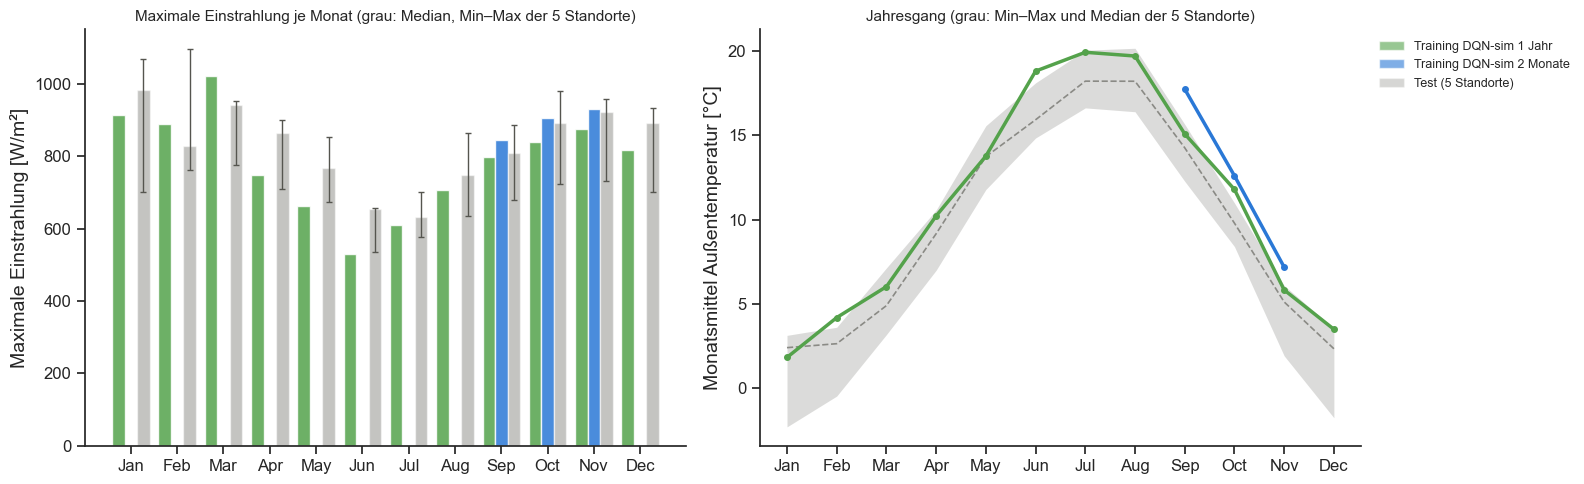

,Stunden,T_amb Mittel [°C],T_amb 5 % [°C],T_amb 95 % [°C],Anteil < 0 °C [%],Anteil > 25 °C [%],Einstrahlung Tag Mittel [W/m²],Einstrahlung 99 % [W/m²]
Datensatz,,,,,,,,
Training DQN-sim 1 Jahr,8759.0,10.9,0.0,24.2,4.9,3.8,271.2,780.8
Training DQN-sim 2 Monate,1676.0,13.1,4.1,24.2,0.3,4.1,233.9,675.4
Test Potsdam,8759.0,9.5,-2.8,22.8,13.1,2.6,215.3,778.9
Test Garmisch-Partenkirchen,8759.0,7.4,-6.5,22.1,20.9,2.0,223.9,693.2
Test Mannheim,8759.0,11.1,-1.7,24.4,8.5,4.3,220.9,782.0
Test Hamburg,8759.0,9.5,-1.0,21.0,8.2,1.9,191.7,752.6
Test Essen,8759.0,10.4,-0.3,21.8,5.8,1.9,188.0,606.2


In [469]:
# ---------- Trainingswetter (1 Jahr, 2 Monate) vs. Testwetter (5 Standorte) ----------
from matplotlib.patches import Patch

WEATHER_TRAINING = ["DQN-sim 1 Jahr", "DQN-sim 2 Monate"]
TEST_COLOR = "#8a8a85"
DAY_RAD = 5          # W/m², darunter = Nacht
YEAR_START = pd.Timestamp("2026-01-01")

weather_sets = {}  # Name -> (DataFrame, Farbe, ist Training)
for agent in WEATHER_TRAINING:
    tr = training[training["folder"] == TRAINING_RUNS[agent][0]]   # Wetter ist für alle Seeds gleich
    weather_sets[f"Training {agent}"] = (tr, AGENT_COLORS[agent], True)
test_weather = ev[ev["agent"] == "Regelbasiert"]                    # Wetter ist für alle Agenten gleich
for city in CITY_MARKERS:
    weather_sets[f"Test {city}"] = (test_weather[test_weather["city"] == city], TEST_COLOR, False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Monatswerte je Datensatz ---
monthly, monthly_rad = {}, {}
for name, (df, _, _) in weather_sets.items():
    month = (YEAR_START + pd.to_timedelta(df["current_time"], unit="h")).dt.month
    monthly[name] = df.groupby(month)["dry_bulb_temperature"].mean()
    monthly_rad[name] = df.groupby(month)["total_horizontal_radiation"].max()
test_names = [n for n in weather_sets if n.startswith("Test")]
months = np.arange(1, 13)

# --- links: maximale Einstrahlung je Monat; Test = Median der 5 Standorte, Fehlerbalken Min-Max ---
ax = axes[0]
test_rad = pd.DataFrame({n: monthly_rad[n] for n in test_names}).reindex(months)
bar_w = 0.27
ax.bar(months - bar_w, monthly_rad["Training DQN-sim 1 Jahr"].reindex(months), width=bar_w,
       color=AGENT_COLORS["DQN-sim 1 Jahr"], alpha=0.85)
ax.bar(months, monthly_rad["Training DQN-sim 2 Monate"].reindex(months), width=bar_w,
       color=AGENT_COLORS["DQN-sim 2 Monate"], alpha=0.85)
test_med = test_rad.median(axis=1)
ax.bar(months + bar_w, test_med, width=bar_w, color=TEST_COLOR, alpha=0.5,
       yerr=[test_med - test_rad.min(axis=1), test_rad.max(axis=1) - test_med],
       error_kw=dict(ecolor="#55554f", lw=1, capsize=2))
ax.set_xticks(months, [pd.Timestamp(2026, m, 1).strftime("%b") for m in months])
ax.set_ylabel("Maximale Einstrahlung [W/m²]")
ax.set_title("Maximale Einstrahlung je Monat (grau: Median, Min–Max der 5 Standorte)", fontsize=11)

# --- rechts: Jahresgang; Test als grauer Bereich (Min-Max über die Standorte) ---
ax = axes[1]
test_monthly = pd.DataFrame({n: monthly[n] for n in test_names})
ax.fill_between(test_monthly.index, test_monthly.min(axis=1), test_monthly.max(axis=1),
                color=TEST_COLOR, alpha=0.3, linewidth=0)
ax.plot(test_monthly.index, test_monthly.median(axis=1), color=TEST_COLOR, lw=1.2, ls="--")
for agent in WEATHER_TRAINING:
    m = monthly[f"Training {agent}"]
    ax.plot(m.index, m.values, color=AGENT_COLORS[agent], lw=2.5, marker="o", ms=4)
ax.set_xticks(range(1, 13), [pd.Timestamp(2026, m, 1).strftime("%b") for m in range(1, 13)])
ax.set_ylabel("Monatsmittel Außentemperatur [°C]")
ax.set_title("Jahresgang (grau: Min–Max und Median der 5 Standorte)", fontsize=11)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
handles = [Patch(facecolor=AGENT_COLORS[a], alpha=0.6, label=f"Training {a}") for a in WEATHER_TRAINING]
handles += [Patch(facecolor=TEST_COLOR, alpha=0.35, label="Test (5 Standorte)")]
axes[1].legend(handles=handles, frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# Kennzahlen je Datensatz
rows = []
for name, (df, _, _) in weather_sets.items():
    t = df["dry_bulb_temperature"]
    r = df["total_horizontal_radiation"]
    rows.append({
        "Datensatz": name,
        "Stunden": len(df) * TIMESTEP_H,
        "T_amb Mittel [°C]": t.mean(),
        "T_amb 5 % [°C]": t.quantile(0.05),
        "T_amb 95 % [°C]": t.quantile(0.95),
        "Anteil < 0 °C [%]": (t < 0).mean() * 100,
        "Anteil > 25 °C [%]": (t > 25).mean() * 100,
        "Einstrahlung Tag Mittel [W/m²]": r[r > DAY_RAD].mean(),
        "Einstrahlung 99 % [W/m²]": r.quantile(0.99),
    })
pd.DataFrame(rows).set_index("Datensatz").round(1)

## 1. Warum sind die 2-Monats-Agenten schlechter?

### 1a. Ganzes Jahr vs. ähnliches Wetter wie im Training

Wenn die 2-Monats-Agenten nur am unbekannten Wetter scheitern, sollten sie bei Wetter, das im 2-Monats-Training vorkam, etwa so gut sein wie die 1-Jahres-Agenten.
„Ähnliches Wetter“ heißt: Die Kombination aus Außentemperatur (2-K-Klassen) und Einstrahlung (100-W/m²-Klassen) kam im Training von DQN-sim 2 Monate mindestens `MIN_SIMILAR_HOURS` Stunden vor (vgl. Konturlinien in der Abbildung oben).
Diese Klassen sind für alle Agenten gleich, weil DQN-real im selben Zeitraum mit sehr ähnlichem Wetter trainiert hat.
Alle Agenten und der regelbasierte Regler werden über genau dieselben Zeitschritte verglichen.
Das Gebäude ist träge, deshalb hängt die Abweichung in einem Zeitschritt auch vom Wetter davor ab. Die Auswahl ist eine Näherung.

Anteil der Testzeit mit ähnlichem Wetter wie im 2-Monats-Training: 65 % (je Standort 54–70 %)
Median [Min, Max] über alle Läufe:


n  \
period                                     agent                   
Ganzes Jahr                                DQN-sim 1 Jahr     25   
                                           DQN-sim 2 Monate   25   
                                           DQN-real 2 Monate   5   
Ähnliches Wetter wie\nim 2-Monats-Training DQN-sim 1 Jahr     25   
                                           DQN-sim 2 Monate   25   
                                           DQN-real 2 Monate   5   

                                                               Kh vs. regelbasiert  \
period                                     agent                                     
Ganzes Jahr                                DQN-sim 1 Jahr      -4.4 % [-9.2, +1.7]   
                                           DQN-sim 2 Monate    +2.2 % [-0.5, +7.3]   
                                           DQN-real 2 Monate   +7.3 % [+5.1, +7.8]   
Ähnliches Wetter wie\nim 2-Monats-Training DQN-sim 1 Jahr      -4.3 % [-9.0, +1.4]   
                                           DQN-sim 2 Monate    +0.8 % [-4.3, +4.3]   
                                           DQN-real 2 Monate  +8.7 % [+7.7, +11.0]   

                                                             Stunden außerhalb vs. regelbasiert  
period                                     agent                                                 
Ganzes Jahr                                DQN-sim 1 Jahr                   -1.6 % [-4.9, -0.2]  
                                           DQN-sim 2 Monate                 +2.2 % [-2.2, +4.3]  
                                           DQN-real 2 Monate                +4.5 % [+3.4, +6.8]  
Ähnliches Wetter wie\nim 2-Monats-Training DQN-sim 1 Jahr                   -3.5 % [-6.5, -0.5]  
                                           DQN-sim 2 Monate                 +2.1 % [-3.8, +4.6]  
                                           DQN-real 2 Monate                +5.0 % [+4.1, +6.8]

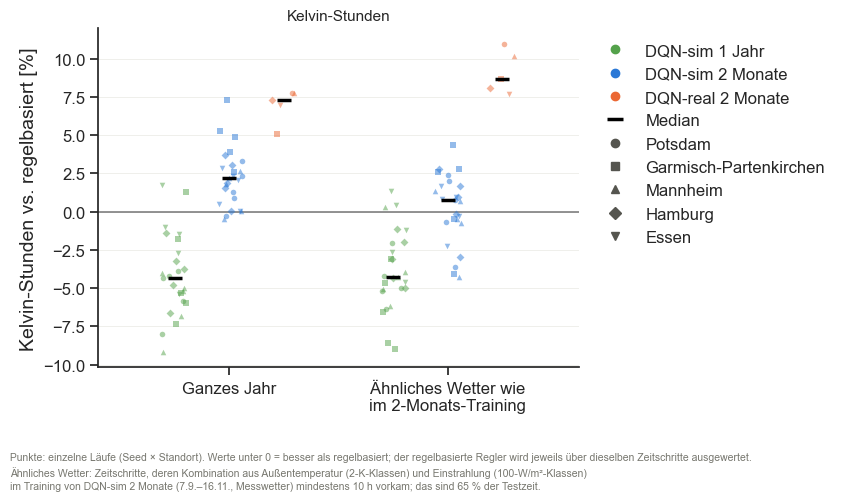

In [470]:
# ---------- Abbildung 1a: ganzes Jahr vs. Zeitschritte mit ähnlichem Wetter wie im 2-Monats-Training ----------
from matplotlib.lines import Line2D

# "Ähnliches Wetter": Klasse aus Außentemperatur (2 K) x Einstrahlung (100 W/m²),
# die im 2-Monats-Training mindestens MIN_SIMILAR_HOURS Stunden vorkam (gleiches Wetter für alle 5 Seeds -> erster Lauf)
SIMILAR_REFERENCE = "DQN-sim 2 Monate"
MIN_SIMILAR_HOURS = 10
T_STEP, RAD_STEP = 2.0, 100.0

def weather_key(df):
    return (np.floor(df["dry_bulb_temperature"] / T_STEP).astype(int).astype(str) + "|"
            + np.floor(df["total_horizontal_radiation"] / RAD_STEP).astype(int).astype(str))

ref_tr = training[training["folder"] == TRAINING_RUNS[SIMILAR_REFERENCE][0]]
hours_per_class = weather_key(ref_tr).value_counts() * TIMESTEP_H
similar_classes = set(hours_per_class[hours_per_class >= MIN_SIMILAR_HOURS].index)
ev["similar_weather"] = weather_key(ev).isin(similar_classes)
share = ev.loc[ev["agent"] == "Regelbasiert"].groupby("city")["similar_weather"].mean() * 100
print(f"Anteil der Testzeit mit ähnlichem Wetter wie im 2-Monats-Training: {share.mean():.0f} % "
      f"(je Standort {share.min():.0f}–{share.max():.0f} %)")

WEATHER_PERIODS = {"Ganzes Jahr": None, "Ähnliches Wetter wie\nim 2-Monats-Training": True}
frames = []
for period, flag in WEATHER_PERIODS.items():
    sub = ev if flag is None else ev[ev["similar_weather"]]
    k = (sub.groupby(["agent", "city", "seed", "run"], dropna=False)[["kh", "outside"]]
         .sum().mul(TIMESTEP_H).reset_index())
    k["period"] = period
    frames.append(k)
kpi_w = pd.concat(frames, ignore_index=True)
kpi_w = kpi_w.join(kpi_w[kpi_w["agent"] == "Regelbasiert"].set_index(["city", "period"])[["kh", "outside"]],
                   on=["city", "period"], rsuffix="_rb")
kpi_w["d_kh"] = (kpi_w["kh"] / kpi_w["kh_rb"] - 1) * 100
kpi_w["d_hours"] = (kpi_w["outside"] / kpi_w["outside_rb"] - 1) * 100

print("Median [Min, Max] über alle Läufe:")
display(kpi_w[kpi_w["agent"] != "Regelbasiert"].groupby(["period", "agent"], sort=False)
        .agg(n=("run", "size"), **{"Kh vs. regelbasiert": ("d_kh", fmt),
                                   "Stunden außerhalb vs. regelbasiert": ("d_hours", fmt)})
        .reindex(pd.MultiIndex.from_product([list(WEATHER_PERIODS), DQN_AGENTS], names=["period", "agent"])))

periods = list(WEATHER_PERIODS)
offsets = dict(zip(DQN_AGENTS, [-0.25, 0.0, 0.25]))
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.axhline(0, color="#7f7f7f", lw=1.2, zorder=1)
for i, period in enumerate(periods):
    for agent, off in offsets.items():
        sub = kpi_w[(kpi_w["period"] == period) & (kpi_w["agent"] == agent)]
        for city, marker in CITY_MARKERS.items():
            vals = sub.loc[sub["city"] == city, "d_kh"]
            ax.scatter(i + off + rng.uniform(-0.06, 0.06, len(vals)), vals, s=16, marker=marker,
                       color=AGENT_COLORS[agent], alpha=0.5, linewidth=0, zorder=2)
        if len(sub):
            ax.scatter(i + off, sub["d_kh"].median(), s=110, marker="_", color="black", linewidth=2.5, zorder=3)
ax.set_xticks(range(len(periods)), periods)
ax.set_xlim(-0.6, len(periods) - 0.4)
ax.set_ylabel("Kelvin-Stunden vs. regelbasiert [%]")
ax.set_title("Kelvin-Stunden", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#ececE8", lw=0.6); ax.set_axisbelow(True)

handles = [Line2D([], [], marker="o", ls="", color=AGENT_COLORS[a], label=a) for a in DQN_AGENTS]
handles += [Line2D([], [], marker="_", ls="", color="black", markersize=12, markeredgewidth=2.5, label="Median")]
handles += [Line2D([], [], marker=m, ls="", color="#55554f", label=c) for c, m in CITY_MARKERS.items()]
ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

note = (
    "Punkte: einzelne Läufe (Seed × Standort). Werte unter 0 = besser als regelbasiert; "
    "der regelbasierte Regler wird jeweils über dieselben Zeitschritte ausgewertet.\n"
    f"Ähnliches Wetter: Zeitschritte, deren Kombination aus Außentemperatur ({T_STEP:.0f}-K-Klassen) und "
    f"Einstrahlung ({RAD_STEP:.0f}-W/m²-Klassen)\nim Training von {SIMILAR_REFERENCE} (7.9.–16.11., Messwetter) "
    f"mindestens {MIN_SIMILAR_HOURS} h vorkam; das sind {share.mean():.0f} % der Testzeit."
)
fig.text(0.01, 0.0, note, fontsize=7.5, color="#77776f", va="bottom", linespacing=1.4)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

### 1b. Welche Aktionen wählen die Agenten?

Anteil der Aktionen je Außentemperatur-Klasse (alle Standorte, alle Seeds).

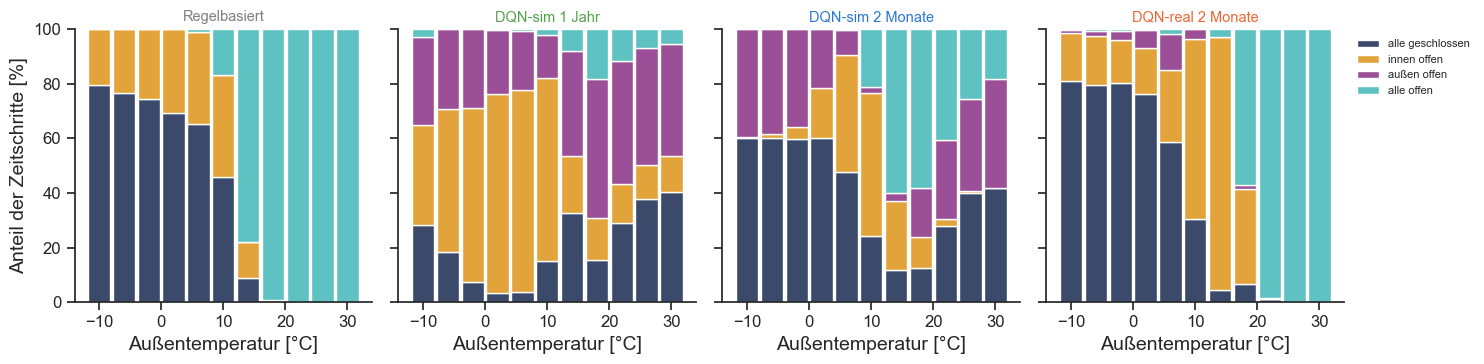

In [471]:
# ---------- Abbildung 1d: Aktionswahl je Außentemperatur ----------
A_BIN = 4.0
ev["t_bin4"] = (np.floor(ev["dry_bulb_temperature"] / A_BIN) * A_BIN).clip(-12, 28)
action_shares = (ev.groupby(["agent", "t_bin4"])["control"].value_counts(normalize=True)
                 .unstack(fill_value=0).reindex(columns=ACTION_ORDER, fill_value=0))

agents_plot = ["Regelbasiert"] + DQN_AGENTS
fig, axes = plt.subplots(1, len(agents_plot), figsize=(15, 3.8), sharey=True)
for ax, agent in zip(axes, agents_plot):
    tab = action_shares.loc[agent] * 100
    bottom = np.zeros(len(tab))
    for a in ACTION_ORDER:
        ax.bar(tab.index + A_BIN / 2, tab[a], width=A_BIN * 0.9, bottom=bottom, color=ACTION_COLORS[a], label=ACTION_NAMES[a])
        bottom += tab[a].values
    ax.set_title(agent, fontsize=10.5, color=AGENT_COLORS[agent])
    ax.set_xlabel("Außentemperatur [°C]")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anteil der Zeitschritte [%]")
axes[-1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 2. DQN-sim vs. DQN-real: gibt es einen Sim-Real-Gap?

DQN-sim 2 Monate und DQN-real 2 Monate unterscheiden sich nur in der Herkunft der Trainingsdaten (Zwilling mit Messwetter vs. Messzelle).
Getestet wird im Zwilling. DQN-sim spielt also auf „Heimvorteil“: Ein besseres Ergebnis von DQN-sim im Zwilling heißt noch nicht, dass DQN-sim auch in der Realität besser ist.

Ein Sim-Real-Gap zeigt sich, wenn dieselbe Aktion in derselben Situation im Zwilling und in der Messzelle **unterschiedlich wirkt**.
Dann lernt jeder Agent die Strategie, die in seiner eigenen Welt funktioniert.

### 2b. Belohnung je Aktion in den Trainingsdaten

Die Belohnung wird mit derselben Funktion wie im Training nachgerechnet (`SimulationEnv._reward`, Modus `ambient_adjusted`).
Die Mittelwerte sind beschreibend, denn die Agenten haben die Aktionen in unterschiedlichen Situationen gewählt. Die Anzahl der Schritte wird mit ausgegeben.

Zelle über dem Band (T_op > 22 °C)
                     mean                               size                 
agent   DQN-real 2 Monate DQN-sim 2 Monate DQN-real 2 Monate DQN-sim 2 Monate
control                                                                      
-1                 -0.030           -0.048               444             2382
 0                 -0.055           -0.081               768             2811
 1                  0.037           -0.065              1783             1657
 2                 -0.005            0.049               685             8609

Zelle unter dem Band (T_op < 20 °C)
                     mean                               size                 
agent   DQN-real 2 Monate DQN-sim 2 Monate DQN-real 2 Monate DQN-sim 2 Monate
control                                                                      
-1                 -0.026           -0.001               483             1900
 0                  0.003            0.022              3183          

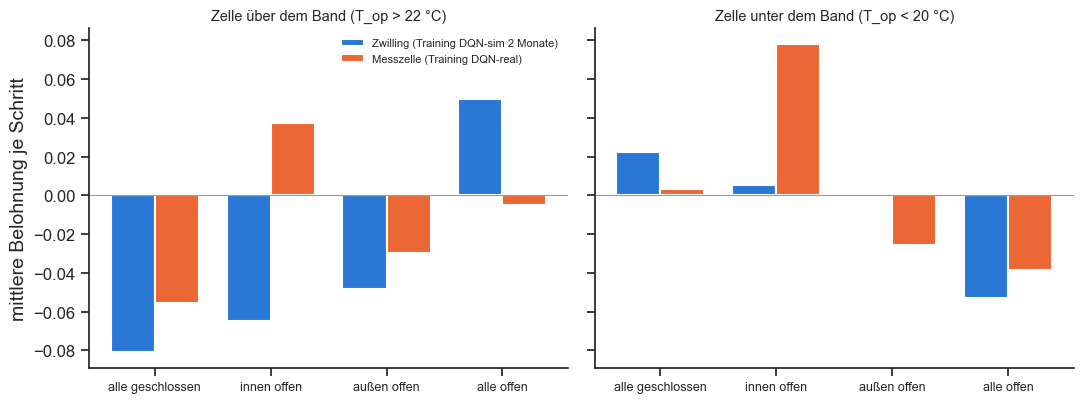

In [472]:
# ---------- Abbildung 2b: mittlere Belohnung je Aktion, Zwilling vs. Messzelle ----------
import sys
sys.path.append(str(REPO))
from connect_protocols.simulation_env import SimulationEnv

GAP_AGENTS = [a for a in DQN_AGENTS if a in ("DQN-sim 2 Monate", "DQN-real 2 Monate")]   # Reihenfolge wie SOURCES_TO_COMPARE
GAP_LABELS = {"DQN-sim 2 Monate": "Zwilling (Training DQN-sim 2 Monate)", "DQN-real 2 Monate": "Messzelle (Training DQN-real)"}
gap_tr = training[training["agent"].isin(GAP_AGENTS) & training["valid_step"]].copy()
x = np.arange(len(ACTION_ORDER))
w = 0.38

reward_env = SimulationEnv(reward="ambient_adjusted")
STATE_COLS = ["dry_bulb_temperature", "total_horizontal_radiation", "operative_temperature"]
prev_states = gap_tr[STATE_COLS].to_dict("records")
next_states = gap_tr[[f"next_{c}" for c in STATE_COLS]].rename(columns=lambda c: c.removeprefix("next_")).to_dict("records")
gap_tr["reward"] = [reward_env._reward(p, n) for p, n in zip(prev_states, next_states)]

REWARD_SITUATIONS = {
    "Zelle über dem Band (T_op > 22 °C)": gap_tr["operative_temperature"] > 22,
    "Zelle unter dem Band (T_op < 20 °C)": gap_tr["operative_temperature"] < 20,
}
fig, axes = plt.subplots(1, len(REWARD_SITUATIONS), figsize=(11, 4.2), sharey=True)
for ax, (situation, mask) in zip(axes, REWARD_SITUATIONS.items()):
    tab = gap_tr[mask].groupby(["agent", "control"])["reward"].agg(["mean", "size"])
    print(situation); print(tab.unstack("agent").round(3)); print()
    for k, agent in enumerate(GAP_AGENTS):
        vals = [tab["mean"].get((agent, a), np.nan) for a in ACTION_ORDER]
        ax.bar(x + (k - 0.5) * w, vals, width=w, color=AGENT_COLORS[agent], label=GAP_LABELS[agent], edgecolor="white", linewidth=1.5)
    ax.axhline(0, color="#9a9a96", lw=0.8)
    ax.set_xticks(x, [ACTION_NAMES[a] for a in ACTION_ORDER], fontsize=9)
    ax.set_title(situation, fontsize=10.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("mittlere Belohnung je Schritt")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()